In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

test_pd = pd.read_json("test.json")
train_pd = pd.read_json("train.json")

# count of malware and goodware
print(test_pd["is_malware"].value_counts(normalize=True)*100)
print(train_pd["is_malware"].value_counts(normalize=True)*100)


is_malware
1    96.264412
0     3.735588
Name: proportion, dtype: float64
is_malware
1    96.257274
0     3.742726
Name: proportion, dtype: float64


# Task1

0        73
1        88
2        79
3        71
4        63
         ..
16320    64
16321    78
16322    84
16323    62
16324    77
Name: api_call_sequence, Length: 16325, dtype: int64
0       98
1       98
2       99
3       85
4       80
        ..
6500    75
6501    83
6502    70
6503    96
6504    78
Name: api_call_sequence, Length: 6505, dtype: int64
              train         test
count  16325.000000  6505.000000
mean      75.030812    86.331130
std        8.951411     9.113511
min       60.000000    70.000000
25%       67.000000    79.000000
50%       75.000000    87.000000
75%       83.000000    94.000000
max       90.000000   100.000000


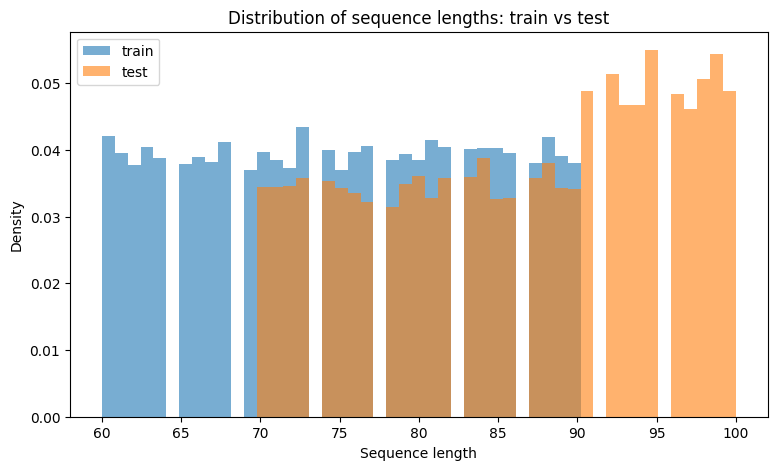

In [4]:

# sequence lengths
print(train_pd["api_call_sequence"].apply(len))
print(test_pd["api_call_sequence"].apply(len))

train_len = train_pd["api_call_sequence"].apply(len)
test_len = test_pd["api_call_sequence"].apply(len)

# Statistiche per confrontarli numericamente
print(pd.DataFrame({"train": train_len.describe(), "test": test_len.describe()}))

# Istogrammi con bin condivisi e density=True (train e test hanno dimensioni diverse)
bins = np.linspace(min(train_len.min(), test_len.min()),
                   max(train_len.max(), test_len.max()), 50)

plt.figure(figsize=(9, 5))
plt.hist(train_len, bins=bins, alpha=0.6, density=True, label="train")
plt.hist(test_len, bins=bins, alpha=0.6, density=True, label="test")
plt.xlabel("Sequence length")
plt.ylabel("Density")
plt.title("Distribution of sequence lengths: train vs test")
plt.legend()
plt.show()


# Task2

Task 2A

Numero di feature (API distinte): 256
Epoca 1/20 - loss media: 0.2013
Epoca 2/20 - loss media: 0.0822
Epoca 3/20 - loss media: 0.0639
Epoca 4/20 - loss media: 0.0521
Epoca 5/20 - loss media: 0.0441
Epoca 6/20 - loss media: 0.0388
Epoca 7/20 - loss media: 0.0349
Epoca 8/20 - loss media: 0.0322
Epoca 9/20 - loss media: 0.0293
Epoca 10/20 - loss media: 0.0270
Epoca 11/20 - loss media: 0.0250
Epoca 12/20 - loss media: 0.0248
Epoca 13/20 - loss media: 0.0240
Epoca 14/20 - loss media: 0.0245
Epoca 15/20 - loss media: 0.0225
Epoca 16/20 - loss media: 0.0192
Epoca 17/20 - loss media: 0.0189
Epoca 18/20 - loss media: 0.0207
Epoca 19/20 - loss media: 0.0185
Epoca 20/20 - loss media: 0.0182
              precision    recall  f1-score   support

           0     0.7733    0.4754    0.5888       122
           1     0.9799    0.9946    0.9872      3143

    accuracy                         0.9752      3265
   macro avg     0.8766    0.7350    0.7880      3265
weighted avg     0.9722    0.9752    0.

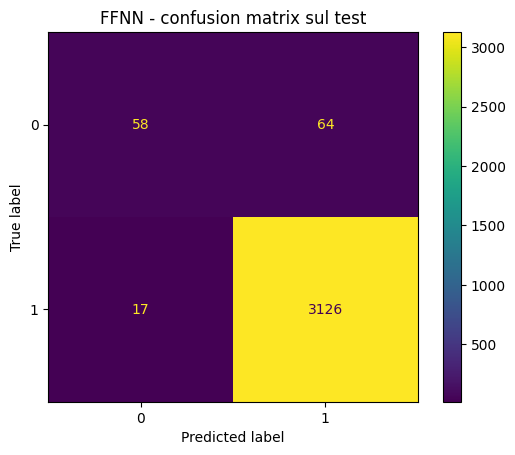

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEQ, LABEL = "api_call_sequence", "is_malware"
torch.manual_seed(42)   # rende i risultati riproducibili

# =========================================================
# 1. FEATURE: conteggio delle singole API (unigrammi)
# =========================================================

# Le sequenze sono già liste di API: diciamo al vectorizer di usarle così come sono
def identity(seq):
    return seq

tr_df, val_df = train_test_split(train_pd, test_size=0.2,
                                 stratify=train_pd[LABEL], random_state=42)

# Ogni API distinta diventa una colonna; ogni sequenza diventa una riga di conteggi
vec = CountVectorizer(analyzer=identity)

X_train = vec.fit_transform(tr_df[SEQ]).toarray()   # fit: impara le colonne SOLO dal train
X_test  = vec.transform(val_df[SEQ]).toarray()        # transform: usa le stesse colonne

# log(1 + x): comprime i conteggi molto grandi (sequenze lunghissime)
X_train = np.log1p(X_train)
X_test  = np.log1p(X_test)

# Standardizzazione: ogni feature ha media 0 e deviazione standard 1
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # calcola media e std sul train
X_test  = scaler.transform(X_test)        # le applica al test

y_train = tr_df[LABEL].values
y_test  = val_df[LABEL].values

print("Numero di feature (API distinte):", X_train.shape[1])

# Conversione in tensori PyTorch (la rete lavora con float32)
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)

# =========================================================
# 2. MODELLO: rete feed-forward con 2 strati nascosti
# =========================================================

class FFNN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),   # strato nascosto 1: 64 neuroni
            nn.ReLU(),
            nn.Linear(64, 32),       # strato nascosto 2: 32 neuroni
            nn.ReLU(),
            nn.Linear(32, 1),        # output: 1 valore (logit) per la classe "malware"
        )

    def forward(self, x):
        return self.net(x).squeeze(1)   # da forma (batch, 1) a (batch,)

model = FFNN(X_train.shape[1])

# =========================================================
# 3. TRAINING
# =========================================================

loss_fn   = nn.BCEWithLogitsLoss()                         # loss per classificazione binaria
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)  # ottimizzatore

# Il DataLoader divide il train in mini-batch da 64 esempi, mescolati a ogni epoca
loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)

EPOCHS = 20
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for xb, yb in loader:
        optimizer.zero_grad()            # azzera i gradienti del passo precedente
        loss = loss_fn(model(xb), yb)    # forward + calcolo della loss
        loss.backward()                  # backpropagation: calcola i gradienti
        optimizer.step()                 # aggiorna i pesi
        total_loss += loss.item()
    print(f"Epoca {epoch + 1}/{EPOCHS} - loss media: {total_loss / len(loader):.4f}")

# =========================================================
# 4. VALUTAZIONE SUL TEST
# =========================================================

model.eval()                 # modalità valutazione
with torch.no_grad():        # niente gradienti: stiamo solo predicendo
    probs = torch.sigmoid(model(X_test_t))   # logit -> probabilità tra 0 e 1
    y_pred = (probs > 0.5).int().numpy()     # soglia 0.5 -> classe 0 o 1

print(classification_report(y_test, y_pred, digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
plt.title("FFNN - confusion matrix sul test")
plt.show()

Task 2B

Numero di feature (API distinte): 5741
Epoca 1/20 - loss media: 0.1347
Epoca 2/20 - loss media: 0.0413
Epoca 3/20 - loss media: 0.0229
Epoca 4/20 - loss media: 0.0174
Epoca 5/20 - loss media: 0.0143
Epoca 6/20 - loss media: 0.0121
Epoca 7/20 - loss media: 0.0115
Epoca 8/20 - loss media: 0.0109
Epoca 9/20 - loss media: 0.0102
Epoca 10/20 - loss media: 0.0092
Epoca 11/20 - loss media: 0.0091
Epoca 12/20 - loss media: 0.0093
Epoca 13/20 - loss media: 0.0092
Epoca 14/20 - loss media: 0.0084
Epoca 15/20 - loss media: 0.0078
Epoca 16/20 - loss media: 0.0081
Epoca 17/20 - loss media: 0.0072
Epoca 18/20 - loss media: 0.0083
Epoca 19/20 - loss media: 0.0074
Epoca 20/20 - loss media: 0.0077
              precision    recall  f1-score   support

           0     0.7768    0.7131    0.7436       122
           1     0.9889    0.9920    0.9905      3143

    accuracy                         0.9816      3265
   macro avg     0.8828    0.8526    0.8670      3265
weighted avg     0.9810    0.9816    0

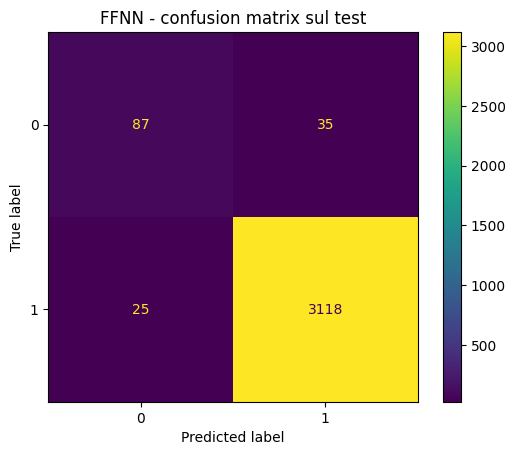

In [15]:
# =========================================================
# 1. FEATURE: bigram BoW (singole API + coppie di API adiacenti)
# =========================================================

def identity(seq):
    return seq

tr_df, val_df = train_test_split(train_pd, test_size=0.2,
                                 stratify=train_pd[LABEL], random_state=42)

vec = CountVectorizer(
    ngram_range=(1, 2),     # 1 = singole API, 2 = coppie di API consecutive
    tokenizer=identity,     # le sequenze sono già liste di token: non spezzarle
    preprocessor=identity,  # nessuna pre-elaborazione del testo
    token_pattern=None,     # evita il warning, visto che usiamo un tokenizer nostro
    lowercase=False,        # mantieni i nomi delle API così come sono
)

X_train = vec.fit_transform(tr_df[SEQ]).toarray()   # fit SOLO sul train
X_test  = vec.transform(val_df[SEQ]).toarray()

# log(1 + x): comprime i conteggi molto grandi (sequenze lunghissime)
X_train = np.log1p(X_train)
X_test  = np.log1p(X_test)

# Standardizzazione: ogni feature ha media 0 e deviazione standard 1
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # calcola media e std sul train
X_test  = scaler.transform(X_test)        # le applica al test

y_train = tr_df[LABEL].values
y_test  = val_df[LABEL].values

print("Numero di feature (API distinte):", X_train.shape[1])

# Conversione in tensori PyTorch (la rete lavora con float32)
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)

# =========================================================
# 2. MODELLO: rete feed-forward con 2 strati nascosti
# =========================================================

class FFNN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),   # strato nascosto 1: 64 neuroni
            nn.ReLU(),
            nn.Linear(64, 32),       # strato nascosto 2: 32 neuroni
            nn.ReLU(),
            nn.Linear(32, 1),        # output: 1 valore (logit) per la classe "malware"
        )

    def forward(self, x):
        return self.net(x).squeeze(1)   # da forma (batch, 1) a (batch,)

model = FFNN(X_train.shape[1])

# =========================================================
# 3. TRAINING
# =========================================================

loss_fn   = nn.BCEWithLogitsLoss()                         # loss per classificazione binaria
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)  # ottimizzatore

# Il DataLoader divide il train in mini-batch da 64 esempi, mescolati a ogni epoca
loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)

EPOCHS = 20
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for xb, yb in loader:
        optimizer.zero_grad()            # azzera i gradienti del passo precedente
        loss = loss_fn(model(xb), yb)    # forward + calcolo della loss
        loss.backward()                  # backpropagation: calcola i gradienti
        optimizer.step()                 # aggiorna i pesi
        total_loss += loss.item()
    print(f"Epoca {epoch + 1}/{EPOCHS} - loss media: {total_loss / len(loader):.4f}")

# =========================================================
# 4. VALUTAZIONE SUL TEST
# =========================================================

model.eval()                 # modalità valutazione
with torch.no_grad():        # niente gradienti: stiamo solo predicendo
    probs = torch.sigmoid(model(X_test_t))   # logit -> probabilità tra 0 e 1
    y_pred = (probs > 0.5).int().numpy()     # soglia 0.5 -> classe 0 o 1

print(classification_report(y_test, y_pred, digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
plt.title("FFNN - confusion matrix sul test")
plt.show()

# Task 3

Task 3A

API distinte: 258 - MAX_LEN: 90
[Integer IDs] Epoca 1/20 - loss: 0.2086
[Integer IDs] Epoca 2/20 - loss: 0.1495
[Integer IDs] Epoca 3/20 - loss: 0.1434
[Integer IDs] Epoca 4/20 - loss: 0.1405
[Integer IDs] Epoca 5/20 - loss: 0.1374
[Integer IDs] Epoca 6/20 - loss: 0.1360
[Integer IDs] Epoca 7/20 - loss: 0.1316
[Integer IDs] Epoca 8/20 - loss: 0.1280
[Integer IDs] Epoca 9/20 - loss: 0.1246
[Integer IDs] Epoca 10/20 - loss: 0.1227
[Integer IDs] Epoca 11/20 - loss: 0.1196
[Integer IDs] Epoca 12/20 - loss: 0.1132
[Integer IDs] Epoca 13/20 - loss: 0.1062
[Integer IDs] Epoca 14/20 - loss: 0.1010
[Integer IDs] Epoca 15/20 - loss: 0.0956
[Integer IDs] Epoca 16/20 - loss: 0.0895
[Integer IDs] Epoca 17/20 - loss: 0.0836
[Integer IDs] Epoca 18/20 - loss: 0.0795
[Integer IDs] Epoca 19/20 - loss: 0.0731
[Integer IDs] Epoca 20/20 - loss: 0.0690

===== Integer IDs =====
              precision    recall  f1-score   support

           0     0.1140    0.0535    0.0728       243
           1     0.9640

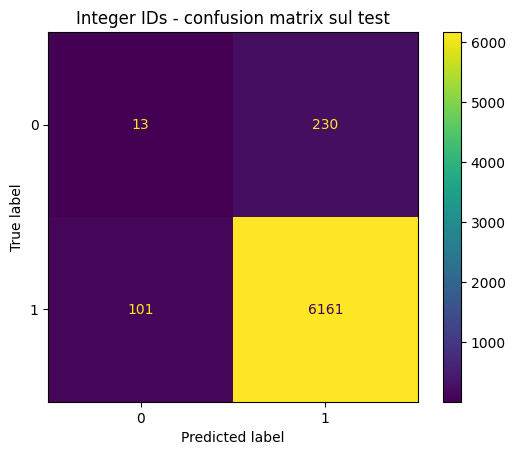

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEQ, LABEL = "api_call_sequence", "is_malware"
torch.manual_seed(42)

# =========================================================
# 1. DA API A ID INTERI (comune a entrambi gli encoding)
# =========================================================

PAD, UNK = 0, 1   # 0 = padding, 1 = API mai vista nel train

# Vocabolario costruito SOLO sul train: ogni API riceve un ID da 2 in su
api_list = sorted({api for seq in train_pd[SEQ] for api in seq})
vocab = {api: i + 2 for i, api in enumerate(api_list)}
VOCAB_SIZE = len(vocab) + 2   # +2 per PAD e UNK

# Lunghezza fissa = sequenza più lunga del train
MAX_LEN = train_pd[SEQ].apply(len).max()
print("API distinte:", len(vocab), "- MAX_LEN:", MAX_LEN)

def encode(seq):
    ids = [vocab.get(api, UNK) for api in seq[:MAX_LEN]]   # tronca tenendo l'inizio
    return ids + [PAD] * (MAX_LEN - len(ids))               # padding fino a MAX_LEN

ids_train = np.array([encode(s) for s in train_pd[SEQ]])   # forma: (n_sequenze, MAX_LEN)
ids_test  = np.array([encode(s) for s in test_pd[SEQ]])

y_train = torch.tensor(train_pd[LABEL].values, dtype=torch.float32)
y_test  = test_pd[LABEL].values

# =========================================================
# 2. ARCHITETTURA 
# =========================================================

class FFNN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64), nn.ReLU(),   # strato nascosto 1
            nn.Linear(64, 32),     nn.ReLU(),   # strato nascosto 2
            nn.Linear(32, 1),                   # output: 1 logit
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

# =========================================================
# 3. TRAINING E VALUTAZIONE 
# =========================================================

def train_and_evaluate(model, X_train, X_test, name, epochs=20):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"[{name}] Epoca {epoch + 1}/{epochs} - loss: {total_loss / len(loader):.4f}")

    model.eval()
    with torch.no_grad():
        y_pred = (torch.sigmoid(model(X_test)) > 0.5).int().numpy()

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, digits=4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
    plt.title(f"{name} - confusion matrix sul test")
    plt.show()
    return y_pred

# =========================================================
# 4. ENCODING (a): ID INTERI + StandardScaler
# =========================================================

# Ogni posizione della sequenza è una feature: la standardizziamo
scaler = StandardScaler()
Xa_train = torch.tensor(scaler.fit_transform(ids_train), dtype=torch.float32)
Xa_test  = torch.tensor(scaler.transform(ids_test),      dtype=torch.float32)

model_a = FFNN(in_dim=MAX_LEN)   # input: MAX_LEN numeri
y_pred_ids = train_and_evaluate(model_a, Xa_train, Xa_test, "Integer IDs")

Task 3B

API distinte: 258 - MAX_LEN: 90
[Embeddings] Epoca 1/20 - loss: 0.1636
[Embeddings] Epoca 2/20 - loss: 0.1155
[Embeddings] Epoca 3/20 - loss: 0.0849
[Embeddings] Epoca 4/20 - loss: 0.0530
[Embeddings] Epoca 5/20 - loss: 0.0323
[Embeddings] Epoca 6/20 - loss: 0.0208
[Embeddings] Epoca 7/20 - loss: 0.0139
[Embeddings] Epoca 8/20 - loss: 0.0129
[Embeddings] Epoca 9/20 - loss: 0.0116
[Embeddings] Epoca 10/20 - loss: 0.0075
[Embeddings] Epoca 11/20 - loss: 0.0080
[Embeddings] Epoca 12/20 - loss: 0.0084
[Embeddings] Epoca 13/20 - loss: 0.0090
[Embeddings] Epoca 14/20 - loss: 0.0071
[Embeddings] Epoca 15/20 - loss: 0.0063
[Embeddings] Epoca 16/20 - loss: 0.0069
[Embeddings] Epoca 17/20 - loss: 0.0052
[Embeddings] Epoca 18/20 - loss: 0.0041
[Embeddings] Epoca 19/20 - loss: 0.0048
[Embeddings] Epoca 20/20 - loss: 0.0053

===== Embeddings =====
              precision    recall  f1-score   support

           0     0.2330    0.1687    0.1957       243
           1     0.9681    0.9784    0.9732 

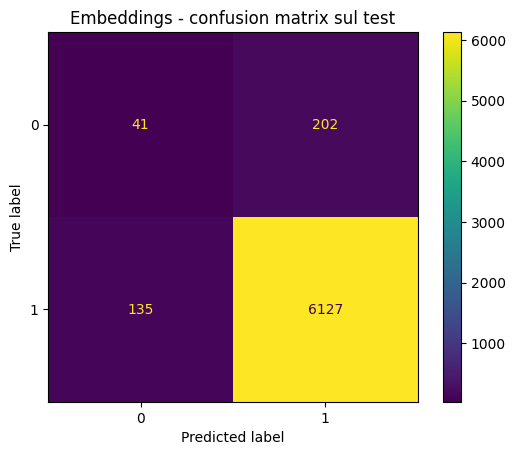

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEQ, LABEL = "api_call_sequence", "is_malware"
torch.manual_seed(42)

# =========================================================
# 1. DA API A ID INTERI 
# =========================================================

PAD, UNK = 0, 1   # 0 = padding, 1 = API mai vista nel train

# Vocabolario costruito SOLO sul train: ogni API riceve un ID da 2 in su
api_list = sorted({api for seq in train_pd[SEQ] for api in seq})
vocab = {api: i + 2 for i, api in enumerate(api_list)}
VOCAB_SIZE = len(vocab) + 2   # +2 per PAD e UNK

# Lunghezza fissa = sequenza più lunga del train
MAX_LEN = train_pd[SEQ].apply(len).max()
print("API distinte:", len(vocab), "- MAX_LEN:", MAX_LEN)

def encode(seq):
    ids = [vocab.get(api, UNK) for api in seq[:MAX_LEN]]   # tronca tenendo l'inizio
    return ids + [PAD] * (MAX_LEN - len(ids))               # padding fino a MAX_LEN

ids_train = np.array([encode(s) for s in train_pd[SEQ]])   # forma: (n_sequenze, MAX_LEN)
ids_test  = np.array([encode(s) for s in test_pd[SEQ]])

y_train = torch.tensor(train_pd[LABEL].values, dtype=torch.float32)
y_test  = test_pd[LABEL].values

# =========================================================
# 2. ARCHITETTURA COMUNE 
# =========================================================

class FFNN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64), nn.ReLU(),   # strato nascosto 1
            nn.Linear(64, 32),     nn.ReLU(),   # strato nascosto 2
            nn.Linear(32, 1),                   # output: 1 logit
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

# =========================================================
# 3. TRAINING E VALUTAZIONE 
# =========================================================

def train_and_evaluate(model, X_train, X_test, name, epochs=20):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"[{name}] Epoca {epoch + 1}/{epochs} - loss: {total_loss / len(loader):.4f}")

    model.eval()
    with torch.no_grad():
        y_pred = (torch.sigmoid(model(X_test)) > 0.5).int().numpy()

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, digits=4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
    plt.title(f"{name} - confusion matrix sul test")
    plt.show()
    return y_pred

# =========================================================
# 4. ENCODING (b): EMBEDDING ADDESTRABILI
# =========================================================

EMB_DIM = 16

class EmbeddingFFNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Tabella addestrabile: ogni ID -> vettore di 16 numeri (il PAD resta a zero)
        self.emb = nn.Embedding(VOCAB_SIZE, EMB_DIM, padding_idx=PAD)
        # Stessa architettura di (a): cambia solo la dimensione dell'input
        self.ffnn = FFNN(in_dim=MAX_LEN * EMB_DIM)

    def forward(self, x):
        x = self.emb(x)         # (batch, MAX_LEN) -> (batch, MAX_LEN, 16)
        x = x.flatten(1)        # -> (batch, MAX_LEN * 16): un unico vettore
        return self.ffnn(x)

# L'embedding vuole ID interi (long), NON scalati
Xb_train = torch.tensor(ids_train, dtype=torch.long)
Xb_test  = torch.tensor(ids_test,  dtype=torch.long)

model_b = EmbeddingFFNN()
y_pred_emb = train_and_evaluate(model_b, Xb_train, Xb_test, "Embeddings")

#Entrambi i modelli raggiungono un’accuracy di circa il 95%, valore vicino a quello di un classificatore che predice sempre la classe maggioritaria e quindi poco informativo a causa del forte sbilanciamento. La macro F1 mostra invece prestazioni limitate: 0.52 per gli ID interi e 0.58 per gli embedding. Gli embedding migliorano soprattutto la recall sulla classe minoritaria, perché imparano una rappresentazione delle API in cui chiamate simili hanno vettori simili, mentre gli ID interi impongono un ordinamento arbitrario. In entrambi i casi l’assenza di una gestione dello sbilanciamento porta il modello a favorire la classe maggioritaria.